# **Aula 06 - Imputação e Normalização de Dados**

## 1. Preparando a base

In [2]:
# Importa as bibliotecas e define o tema dos gráficos
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from google.colab import files
uploaded = files.upload()

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

sns.set_theme(style="whitegrid", palette="colorblind")

Saving imoveis_sao_paulo.csv to imoveis_sao_paulo.csv


Este bloco prepara o ambiente importando as bibliotecas que vão ser usadas ao longo do notebook e define a aparência dos gráficos.

* **pathlib (`Path`)**: representa o caminho do arquivo da base de forma que funcione em qualquer sistema operacional.
* **NumPy**: realiza cálculos numéricos com vetores, como `np.log`, `np.log1p` e `np.where`.
* **pandas**: trabalha com tabelas. Lê o CSV, renomeia colunas, remove duplicatas, agrupa os dados e preenche lacunas.
* **Matplotlib**: cria as figuras e os painéis dos gráficos.
* **Seaborn**: construído sobre o Matplotlib, produz gráficos estatísticos, como histogramas e gráficos de barras.
* **SciPy (`stats`)**: fornece funções estatísticas, como a assimetria (`skew`) e as transformações Box-Cox e Yeo-Johnson.
* **scikit-learn**: fornece os escaladores `StandardScaler`, `RobustScaler` e `MinMaxScaler` e o `PowerTransformer`, usados nas seções de escalonamento e transformação.

Por fim, `sns.set_theme` define um padrão visual para todos os gráficos do notebook: fundo branco com grade (`whitegrid`), que facilita a leitura dos valores, e uma paleta de cores acessível (`colorblind`).

In [3]:
# Novos nomes para as colunas com espaços e símbolos
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

# Carrega a base, remove duplicatas e identifica o tipo de imóvel
imoveis = (
    pd.read_csv("imoveis_sao_paulo.csv")
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign(
        property_type=lambda df: np.where(
            df["floor"].isna(),
            "casa",
            "apartamento",
        )
    )
)

O dicionário `column_names` define os novos nomes para as colunas que tem espaços e símbolos, e que passa a seguir o padrão snake_case. Esse padrão facilita o acesso às colunas no código.

Em seguida, a base é carregada e passa por uma sequência de ajustes:

1. **Renomeação das colunas**, usando o dicionário anteriormente.
2. **Remoção de linhas duplicadas**, para que um mesmo anúncio não seja contado mais de uma vez nas estatísticas e nos gráficos.
3. **Renumeração do índice**, já que a remoção de duplicatas deixa lacunas na numeração das linhas.
4. **Criação da coluna `property_type`**: imóveis sem andar informado (`floor` vazio) são classificados como casa, e os demais como apartamento.

Com isso podemos pensar também que um valor ausente pode ter um significado importante para a analie dos dados e modificar uma conclusão, visto que a falta de andar não é um erro, e sim uma característica das casas. Ao registrar isso em uma nova coluna, essa informação deixa de estar escondida e pode ser usada nas análises seguintes.

### 1.1 Os três problemas da aula

Foi utilizado o conjunto de dados da aula para exemplificar os problemas.

* **Valores ausentes:** Se não forem tratadas, as lacunas causam problemas para analisar o conjunto, pois podem ser selecionados subconjuntos diferentes ao descartar as linhas com valores ausentes.

* **Escalas incompatíveis:** Na base de dados utilizada na aula temos registros dos aluguéis de imóveis, com dados como quantidade de quartos em unidade, área do imóvel em metro quadrado e valor de aluguel em reais, ou seja, as variáveis estão em diferentes grandezas, o que pode dificultar a execução de alguns algoritmos. Nos gráficos, há predominância de um fator que parece ser o mais importante, que no caso seria o aluguel, mas isso acontece apenas por causa da unidade.

* **Cauda longa:** A maioria dos aluguéis fica abaixo de R$ 5.100, mas poucos imóveis muito caros chegam a uma diferença gritante. Essa assimetria pode causar problemas nos resultados das análises, pois a média vai ser puxada por esses outliers e gerar uma representação errada da realidade.

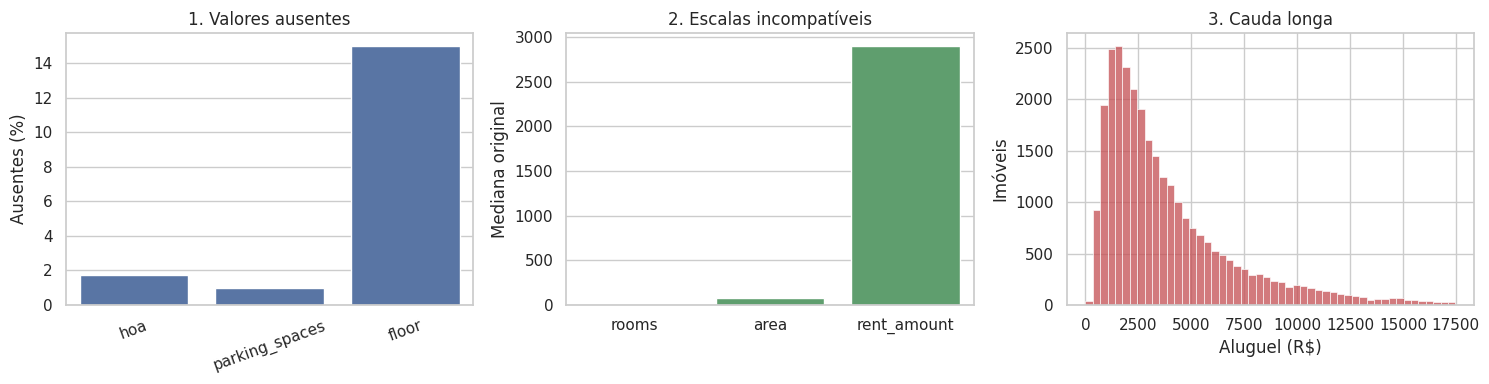

In [4]:
# Valores exibidos em cada painel da figura
missing = (
    imoveis[["hoa", "parking_spaces", "floor"]]
    .isna()
    .mean()
    .mul(100)
)

scales = (
    imoveis[["rooms", "area", "rent_amount"]]
    .median()
)

limit = imoveis["rent_amount"].quantile(.99)

# Figura-resumo com os três problemas da aula
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    x=missing.index,
    y=missing.values,
    ax=axes[0],
    color="#4C72B0",
)
axes[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",
)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    x=scales.index,
    y=scales.values,
    ax=axes[1],
    color="#55A868",
)
axes[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel="",
)

sns.histplot(
    imoveis["rent_amount"],
    bins=50,
    binrange=(0, limit),
    ax=axes[2],
    color="#C44E52",
)
axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

* **Valores ausentes:** Em `hoa` (cerca de 1,7%) e `parking_spaces` (cerca de 1%), as poucas lacunas sugerem falhas pontuais de cadastro, que podem ser tratadas por imputação sem grande impacto na base. Em `floor` (cerca de 15%), a proporção é alta demais para ser acaso, há um motivo para a falta dessa informação. Por isso, antes de preencher qualquer valor, é preciso investigar a causa, para não criaria um dado falso.

* **Escalas incompatíveis:** o fato de o aluguel dominar o gráfico não significa que ele seja a variável mais importante, e sim que está medido em uma unidade com números maiores. Uma diferença de 1 quarto entre dois imóveis é relevante, mas, numericamente, vale muito menos que uma diferença de valor no alguel. Se as variáveis forem usadas assim em um algoritmo baseado em distância, o resultado dependerá quase só do aluguel. Por isso, elas precisam ser colocadas em escalas comparáveis antes da modelagem.

* **Cauda longa:** a concentração de imóveis entre R$ 1.000 e R$ 5.000, seguida de uma cauda que se estende para a direita, mostra que o mercado é formado por muitos imóveis de aluguel moderado e poucos imóveis muito caros. Esses poucos imóveis puxam a média para cima, então a média deixa de representar o aluguel real, e a mediana se torna uma medida mais adequada. A cauda também faz com que os imóveis caros tenham peso exagerado em análises e modelos, o que indica a necessidade de uma transformação para reduzir a assimetria.

Em resumo, os três gráficos mostram que a base precisa de tratamento antes de ser analisada.

## 2. Ausência estrutural

In [5]:
# Número de imóveis e proporção sem andar, por tipo
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=(
            "floor",
            lambda x: (
                x
                .isna()
                .mean()
            ),
        ),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


O código separa os imóveis por tipo e calcula, em cada grupo, a quantidade de imóveis e a proporção sem andar informado.

O resultado mostra que todos os 25.024 apartamentos têm andar informado, enquanto todas as 4.415 casas estão sem andar. As casas representam cerca de 15% da base, exatamente a proporção de lacunas em `floor` vista no gráfico de valores ausentes. Ou seja, todas as lacunas dessa coluna vêm das casas.

Isso indica uma **ausência estrutural**: o andar descreve a posição de uma unidade dentro de um prédio e, por isso, não se aplica a casas. Não houve erro de cadastro, a informação simplesmente não existe para esse tipo de imóvel.

Por esse motivo, `floor` **não deve ser imputada**. Preencher o andar de uma casa com a média ou a mediana dos apartamentos criaria um valor sem significado, e um modelo poderia aprender um padrão falso a partir dele. A solução adotada foi registrar essa característica na coluna `property_type`, que torna explícita a informação que antes estava escondida na lacuna.

## 3. Imputação: o impacto das alternativas

In [6]:
# Função de apagamento e base-gabarito
rng = np.random.default_rng(42)

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

Para avaliar uma imputação, seria preciso comparar o valor estimado com o valor verdadeiro em uma lacuna real, porém, o valor verdadeiro é desconhecido, e não há como medir o erro. A solução é montar um experimento que parte de dados completos, apagar alguns valores de propósito, após isso irá imputá-los e comparar as estimativas com os valores originais.

* **O sorteador `rng`:** é um gerador de números aleatórios com semente fixa. A semente faz com que a sequência de sorteios seja sempre a mesma, então quem executar o notebook vai apagar exatamente os mesmos valores e obter os mesmos resultados, para que possa torna o experimento reproduzível.

* **A função `erase_at_random`:** recebe uma coluna e a proporção de valores a apagar. Ela sorteia um número entre 0 e 1 para cada linha e, quando o sorteio fica abaixo de share, troca o valor por NaN com o método. Por exemplo, com share = 0.10, cerca de 10% dos valores são apagados. Como todas as linhas têm a mesma chance de serem escolhidas, as lacunas são totalmente aleatórias.

* **A base-gabarito `imoveis_true`:** contém apenas os imóveis com `hoa` e `parking_spaces` preenchidos, pois os imóveis que já tinham lacunas reais nessas colunas foram removidos. Ela guarda os valores verdadeiros de referência: como não tem lacunas próprias, toda posição apagada depois terá um valor original para comparação. O `reset_index` renumera as linhas, que ficaram com buracos após a remoção.

In [7]:
# Apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

São criadas lacunas em três colunas de tipos diferentes, porque cada tipo de variável exige uma estratégia de imputação diferente:

* `rooms` é uma variável discreta, que só assume valores inteiros, com 10% apagados;
* `rent_amount` é uma variável contínua e assimétrica, com 15% apagados;
* `furniture` é uma variável categórica, com as categorias mobiliado e não mobiliado, com 8% apagados.

A base `imoveis_true` continua intacta, e as lacunas ficam apenas na cópia `imoveis_missing`. Assim, o valor original de cada posição apagada continua disponível para comparação.

In [8]:
# Quantidade e proporção de valores apagados por coluna
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(
        proporcao=lambda x: (
            x.ausentes / len(imoveis_missing)
        ).round(3)
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


Foram apagados 2.783 valores de `rooms`, 4.308 de `rent_amount` e 2.254 de `furniture`. As proporções obtidas (9,7%, 15,0% e 7,9%) ficam muito próximas das proporções definidas em código.

Elas não são exatamente iguais porque cada linha passa por um sorteio independente, em vez de se escolher um número fixo de linhas. Essa pequena variação é esperada e confirma que o apagamento funcionou como planejado.

**Por que o mecanismo de ausência importa?**

O motivo pelo qual um valor está ausente afeta a qualidade da imputação. Existem três mecanismos:

* **MCAR (ausência completamente aleatória):** a chance de faltar não depende de nada. Exemplo: um erro aleatório de sistema apaga o aluguel de alguns imóveis. Nesse caso, os dados observados representam bem a base, e a imputação não gera viés.
* **MAR (ausência aleatória condicionada):** a chance de faltar depende de outra variável observada. Exemplo: anúncios de um certo tier deixam de informar as vagas com mais frequência. Nesse caso, imputar por grupo, usando a variável que explica a ausência, reduz o viés.
* **MNAR (ausência não aleatória):** a chance de faltar depende do próprio valor ausente. Exemplo: os donos de imóveis muito caros preferem não informar o aluguel. Nesse caso, nenhuma estatística dos valores observados recupera o valor real, e a imputação tende a subestimar os aluguéis.

O experimento desta seção apaga valores ao acaso, ou seja, simula o caso MCAR, que é o mais favorável. Por isso, os erros medidos aqui mostram o desempenho das estratégias no melhor cenário. Na base real, se a ausência seguir outro mecanismo, os erros podem ser maiores.

### 3.1 Média, mediana e mediana agrupada

In [9]:
# Constantes para a imputação simples
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

print(f"Média:   R$ {rent_mean:,.2f}")
print(f"Mediana: R$ {rent_median:,.2f}")

Média:   R$ 4,054.54
Mediana: R$ 2,901.58


Este bloco calcula as duas constantes usadas na imputação simples do aluguel: a média e a mediana. Elas são calculadas apenas com os valores observados, pois o pandas ignora os valores ausentes. Na imputação simples, todas as lacunas recebem o mesmo valor.

A média fica acima da mediana, isso acontece por causa da cauda longa, a média usa o valor de todos os aluguéis e, por isso, é puxada para cima pelos poucos imóveis muito caros. A mediana depende apenas da posição central dos dados e não é afetada por esses valores extremos.

Na prática, isso significa que a média representa mal o imóvel típico desta base. Ao preencher as lacunas com ela, a maioria dos imóveis receberia um aluguel acima do real. Por isso, espera-se que a mediana produza estimativas mais próximas dos valores verdadeiros, o que será verificado com o cálculo do erro.

**OBS:** Adicionei o print dos resultados para verificar a diferença

In [10]:
# Imputação pela mediana de cada tier
rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

In [11]:
imoveis_missing.groupby("tier").rent_amount.median()

,rent_amount
tier,
affordable,1350.0
luxury,7350.0
mid,2490.0
premium,4570.0


Este bloco preenche as lacunas do aluguel com a mediana do tier de cada imóvel, em vez de usar uma única mediana para toda a base.

* `groupby("tier")` separa os imóveis por tier
* `transform` calcula a mediana do aluguel dentro de cada tier e preenche as lacunas daquele grupo com ela. O `transform` devolve uma coluna do mesmo tamanho da original, com cada valor na sua posição
* `fillna(rent_median)` funciona como reserva: se algum tier não tiver nenhum aluguel observado, sua mediana não pode ser calculada, e as lacunas desse grupo recebem a mediana global.

A vantagem dessa estratégia é usar uma informação adicional sobre o imóvel. O aluguel típico varia bastante de um tier para outro, e uma mediana única ignora essa diferença: um imóvel de padrão alto receberia um aluguel abaixo do real, e um de padrão baixo, um aluguel acima. Com a mediana por tier, cada lacuna recebe um valor mais próximo dos imóveis semelhantes a ela.

Por isso, espera-se que essa estratégia tenha um erro menor que a média e a mediana globais.

In [12]:
# Versões do aluguel a comparar
rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

Este bloco reúne cinco versões da coluna de aluguel para que possam ser comparadas

* **Original:** os valores verdadeiros, do gabarito
* **Com lacunas:** a coluna após o apagamento, com 15% dos valores ausentes
* **Média:** as lacunas preenchidas com a média dos aluguéis observados
* **Mediana:** as lacunas preenchidas com a mediana dos aluguéis observados
* **Mediana por tier:** as lacunas preenchidas com a mediana do tier de cada imóvel.

Organizar as versões dessa forma permite gerar todos os gráficos com um único laço no bloco seguinte, em vez de repetir o código cinco vezes.

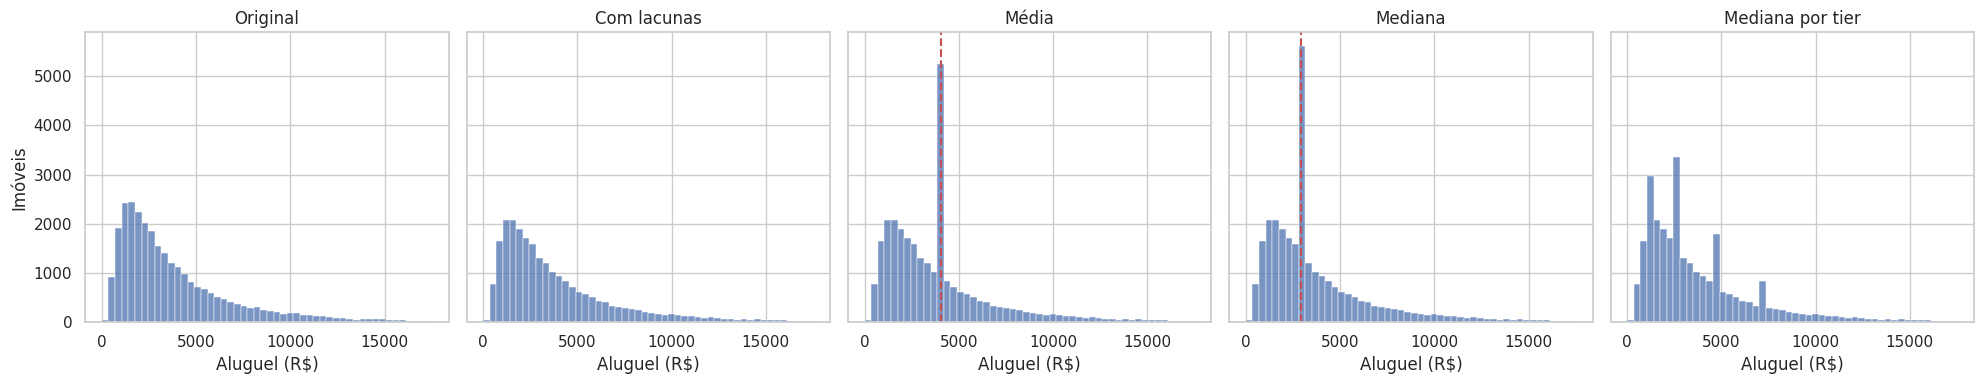

In [13]:
# Histograma de cada versão do aluguel
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

limit = imoveis_true.rent_amount.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),
        bins=50,
        binrange=(0, limit),
        ax=ax,
        color="#4C72B0",
    )
    ax.set(
        title=label,
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    if label == "Média":
        ax.axvline(
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()
plt.show()

Os cinco histogramas mostram como cada estratégia altera a distribuição do aluguel. Todos usam a mesma escala vertical e o mesmo recorte para que possam ser comparados diretamente. Nos painéis da média e da mediana, a linha tracejada marca o valor usado para preencher as lacunas.

O painel **Com lacunas** tem a mesma forma do **Original**, mas com barras um pouco mais baixas, já que 15% dos valores foram apagados de forma aleatória.

Nos painéis **Média** e **Mediana**, aparece um **pico artificial** exatamente na linha tracejada. Isso acontece porque todas as cerca de 4.300 lacunas recebem o mesmo valor e se acumulam em uma única barra. A distribuição deixa de refletir os dados reais, pois surge uma concentração de imóveis com um aluguel que não corresponde à realidade.

No painel **Mediana por tier**, as lacunas são distribuídas entre vários valores, um por tier. Os picos ainda existem, mas são menores e ficam espalhados, de modo que o histograma fica mais parecido com o original.

Os histogramas mostram o efeito de cada estratégia sobre a **forma** da distribuição.

###   *3.1.1 Erro absoluto médio (MAE)*

In [14]:
# Posições apagadas e seus valores verdadeiros
rent_missing = imoveis_missing.rent_amount.isna()

truth = imoveis_true.loc[rent_missing, "rent_amount"]

Para medir o erro das imputações, é preciso comparar cada valor imputado com o valor verdadeiro na mesma posição.

* `rent_missing` marca com `True` as linhas em que o aluguel foi apagado e com `False` as demais
* `truth` usa essa marcação para buscar no gabarito o aluguel verdadeiro apenas dessas linhas.

O cálculo do erro considera somente as posições apagadas, pois nas posições que não foram apagadas, o valor não foi alterado pela imputação e o erro é zero e se fosse considerado afetaria o resultado real.

In [15]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series(
        {
            "Média": (
                (truth - rent_mean)
                .abs()
                .mean()
            ),
            "Mediana": (
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier": (
                (truth - rent_group[rent_missing])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)",
    )
    .round(2)
    .to_frame()
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


### 3.2 Moda e variáveis discretas

### 3.3 Resumo da imputação

## 4. Escalonamento: a régua muda, a forma não

### 4.1 Três escaladores

### 4.2 Sensibilidade a extremos

## 5. Transformações: a forma muda

### 5.1 Aluguel positivo: log e Box-Cox

### 5.2 Distância com zeros: log1p e Yeo-Johnson

### 5.3 Resumo das transformações

## 6. Aplicação e comparação final

### 6.1 Registrar as lacunas

### 6.2 Imputar pela mediana do grupo

### 6.3 Reduzir as caudas

### 6.4 Antes e depois

## 7. Guia rápido

## Síntese

## Perguntas para consolidar

## Para casa